# Percepción de inseguridad y victimización en Chile (ENUSC 2023)

## Entrega 3: Modelo básico

Regresión logística que predice si una persona percibe que la delincuencia aumentó en su barrio, a partir de variables sociodemográficas, de victimización y de inseguridad.

### Modelo de predicción de percepción de aumento delictual en barrios urbanos ENUSC 2023

### Parte 1: Cargar datos y definir variable objetivo

In [1]:
import pandas as pd


df = pd.read_csv("../datos/base-usuario-20-enusc-2023.csv")

# Filtrar respuestas validas
df = df[df["P_AUMENTO_BARRIO"].isin([1, 2, 3])]

# Crear variable binaria: 1 = percepcion de aumento
# y 0 para el caso de se mantuvo y disminuyo
df["percibe_aumento"] = df["P_AUMENTO_BARRIO"].apply(lambda x: 1 if x == 1 else 0)


Tenemos que nuestra variable objetivo (dependiente) es P_AUMENTO_BARRIO, siendo asi la percepcion de la delicuencia los ultimos 12 meses, como se puede apreciar.

### Parte 2: Selección de variables predictoras y limpieza

Seleccionamos las variables que pueden estar relacionadas con la percepción de inseguridad, como edad, sexo, educación, NSE, victimización, exposición al delito e inseguridad diurna y nocturna.

In [2]:
features = [
    'rph_edad',           # Edad
    'rph_sexo',           # Sexo
    'rph_nivel',          # Nivel educacional
    'rph_nse',            # Nivel socioeconómico
    'VH_DC',              # Victimizacion
    'P_EXPOS_DELITO',     # Exposición a delitos
    'P_INSEG_OSCURO_1',   # Inseguridad de noche
    'P_INSEG_DIA_1'       # Inseguridad de dia
]

# Reemplazo de valores especiales por NaN
df[features] = df[features].replace([88, 99, 85], pd.NA)

# Eliminar filas con datos faltantes
df_model = df.dropna(subset=features + ['percibe_aumento'])

# Verificamos clases
print(df_model["percibe_aumento"].value_counts())


percibe_aumento
1    21607
0    19850
Name: count, dtype: int64


Se realizo la limpieza de los datos, de manera de reemplazar los datos por NA que no son relevantes  para el modelo como: 

85. No aplica
88. No sabe
99. No responde

Para asi luego eliminarlos mas facilmente, esto nos permite garantizar que el modelo no esté sesgado por respuestas incompletas o inconsistentes.

### Parte 3: División en entrenamiento y prueba

In [3]:
from sklearn.model_selection import train_test_split

X = df_model[features]
y = df_model["percibe_aumento"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

Usaremos aprendizaje supervisado, dividiendo el conjunto de datos con un 70% de los datos para el entrenamiento y un 30% de los datos para las pruebas de predicción.

### Parte 4: Entrenamiento del modelo de regresión logística

In [4]:
from sklearn.linear_model import LogisticRegression

# Creamos el modelo y lo entrena
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)



LogisticRegression(max_iter=1000)

Para poder llevar a cabo el aprendizaje supervisado usaremos un modelo de regresion logistica, debido que es muy util al predecir la probabilidad de que un caso pertenezca a una determinada clase.

### Parte 5: Predicciones y evaluación del modelo

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.67      0.65      0.66      5955
           1       0.68      0.71      0.70      6483

    accuracy                           0.68     12438
   macro avg       0.68      0.68      0.68     12438
weighted avg       0.68      0.68      0.68     12438



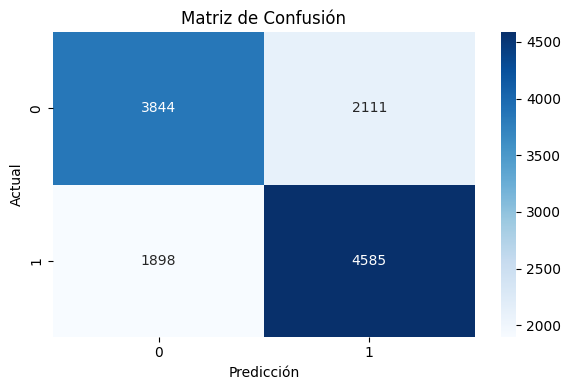

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Predicciones
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Reporte de clasificación
print("REPORTE DE CLASIFICACIÓN")
print(classification_report(y_test, y_pred))

# Matriz de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


Podemos concluir lo siguiente: 
Vemos que el modelo predice mejor la clase positiva, lo que es esperable ya que es la mayoría.

La diferencia entre clases es pequeña, lo que nos indica que el modelo esta bien balanceado.

Tenemos una Exactitud(Accuracy) del 68% siendo aceptable para un fenómeno subjetivo como percepción ciudadana.

### Parte 6: Curva ROC y AUC

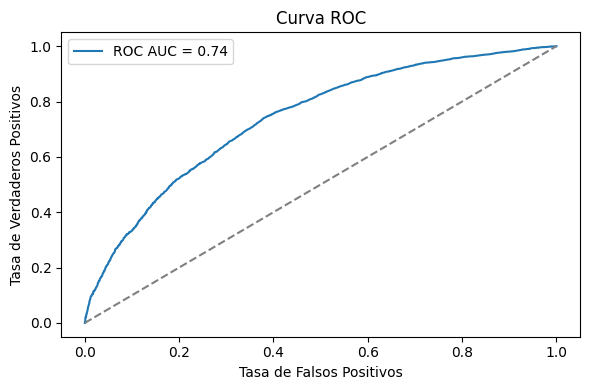

In [6]:
# Curva ROC 
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC")
plt.legend()
plt.tight_layout()
plt.show()


Se obtuvo un AUC fue 0.74 siendo una discriminación aceptable, lo que indica que el modelo distingue bien entre personas que creen o no que aumentó la delincuencia.